<a href="https://colab.research.google.com/github/karimovamaria279/figure-skating-ml-analysis/blob/main/olympics_singles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка графиков
plt.style.use('ggplot')
%matplotlib inline

# Ссылка на скачивание файла с Kaggle
url = "https://www.kaggle.com/api/v1/datasets/download/nupurgudigar/olympic-figure-skating-singles-scores-20062026/olympics_singles_agg.csv"

# Загружаем данные в датафрейм
df = pd.read_csv(url)

print("Размер данных:", df.shape)
print("\nКолонки:")
print(df.columns.tolist())
print("\nПервые 5 строк:")
display(df.head())

Размер данных: (357, 18)

Колонки:
['year', 'gender', 'final_rank', 'skater', 'nation', 'total_tss', 'sp_rank', 'fs_rank', 'tss_sp', 'tes_sp', 'pcs_sp', 'tss_fs', 'tes_fs', 'pcs_fs', 'tes_total', 'pcs_total', 'tech_dominance', 'medal']

Первые 5 строк:


,year,gender,final_rank,skater,nation,total_tss,sp_rank,fs_rank,tss_sp,tes_sp,pcs_sp,tss_fs,tes_fs,pcs_fs,tes_total,pcs_total,tech_dominance,medal
0,2026,M,1,SHAIDOROV Mikhail,KAZ,291.58,5,1.0,92.94,52.45,40.49,198.64,114.68,83.96,167.13,124.45,57.32%,1
1,2026,M,2,KAGIYAMA Yuma,JPN,280.06,2,6.0,103.07,56.50,46.57,176.99,92.15,85.84,148.65,132.41,52.89%,2
2,2026,M,3,SATO Shun,JPN,274.90,9,3.0,88.70,46.77,41.93,186.20,101.85,84.35,148.62,126.28,54.06%,3
3,2026,M,4,CHA Junhwan,KOR,273.92,6,5.0,92.72,50.08,42.64,181.20,95.16,87.04,145.24,129.68,52.83%,0
4,2026,M,5,GOGOLEV Stephen,CAN,273.78,10,2.0,87.41,48.23,39.18,186.37,103.22,83.15,151.45,122.33,55.32%,0


In [3]:
# Анализ пропусков
print("Пропуски в данных:")
print(df.isnull().sum())

# Удаляем строки, где нет итогового балла или оценок за технику/артистизм
df = df.dropna(subset=[df.columns[3]])

Пропуски в данных:
year              0
gender            0
final_rank        0
skater            0
nation            0
total_tss         0
sp_rank           0
fs_rank           6
tss_sp            0
tes_sp            0
pcs_sp            0
tss_fs            0
tes_fs            0
pcs_fs            0
tes_total         0
pcs_total         0
tech_dominance    0
medal             0
dtype: int64


In [8]:
# Настраиваем общий стиль для всех графиков
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#F4F8FB"})

ice_palette = ["#0B3C5D", "#328CC1", "#7AB6DE", "#D9E8F5"]
sns.set_palette(ice_palette)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

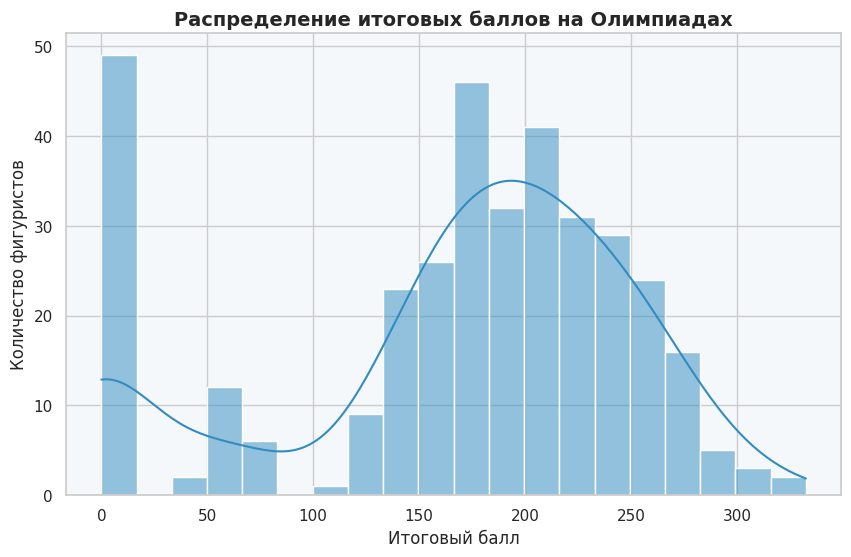

In [9]:
plt.figure(figsize=(10, 6))
sns.histplot(df['total_tss'], bins=20, kde=True, color="#328CC1", edgecolor="white")
plt.title('Распределение итоговых баллов на Олимпиадах')
plt.xlabel('Итоговый балл')
plt.ylabel('Количество фигуристов')
plt.show()

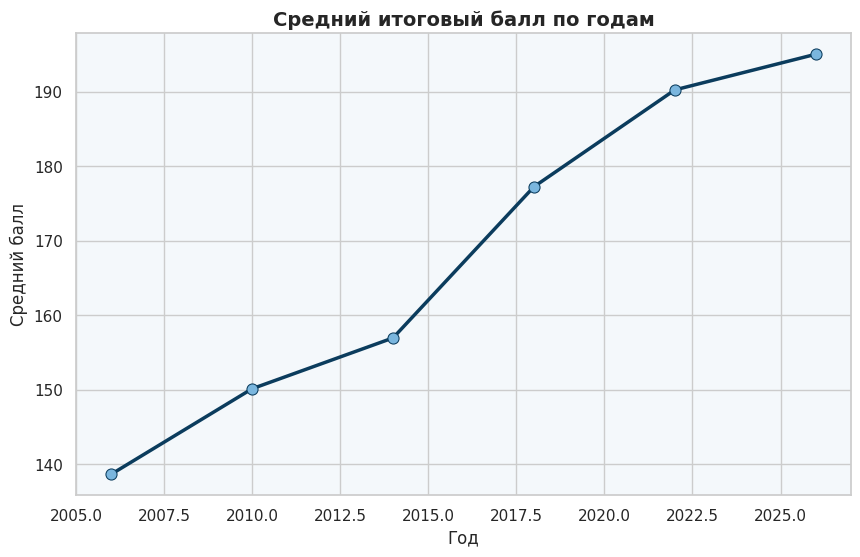

In [10]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='year', y='total_tss', marker='o',
             color="#0B3C5D", markerfacecolor="#7AB6DE", markeredgecolor="#0B3C5D",
             linewidth=2.5, markersize=8, errorbar=None)
plt.title('Средний итоговый балл по годам')
plt.xlabel('Год')
plt.ylabel('Средний балл')
plt.show()

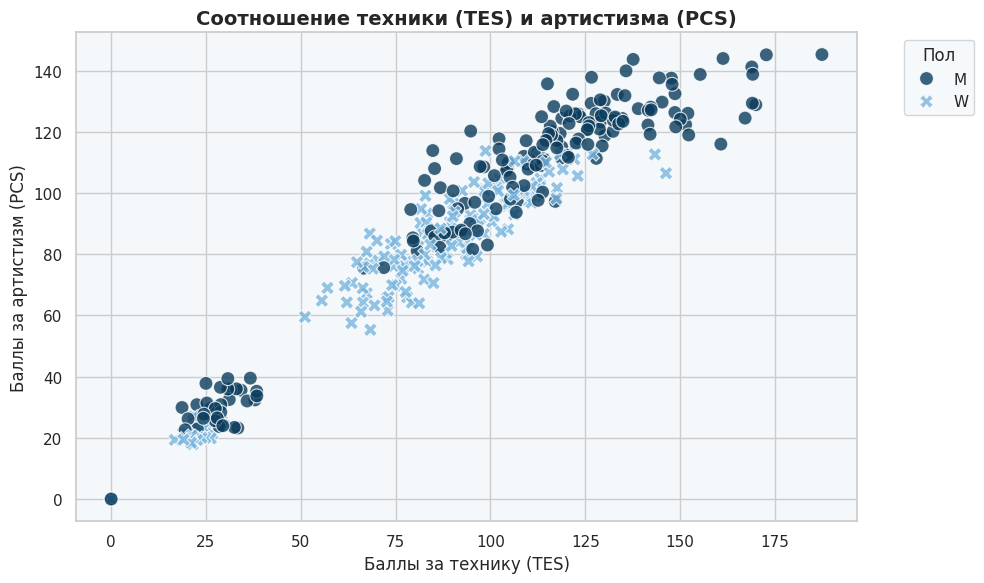

In [16]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='tes_total', y='pcs_total',
                hue='gender', style='gender', s=100, alpha=0.8,
                palette={"M": "#0B3C5D", "W": "#7AB6DE"})
plt.title('Соотношение техники (TES) и артистизма (PCS)')
plt.xlabel('Баллы за технику (TES)')
plt.ylabel('Баллы за артистизм (PCS)')
plt.legend(title='Пол', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Выбираем признаки (X) и целевую переменную (y)
X = df[['tes_total', 'pcs_total']]
y = df['total_tss']

# 2. Делим данные на обучающую (80%) и тестовую (20%) выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Модель 1: Линейная регрессия (базовая модель)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# 4. Модель 2: Случайный лес
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 5. Оценка качества моделей
print("=== Линейная регрессия ===")
print(f"R2 (точность): {r2_score(y_test, y_pred_lr):.3f}")
print(f"RMSE (ошибка): {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.3f}")

print("\n=== Случайный лес ===")
print(f"R2 (точность): {r2_score(y_test, y_pred_rf):.3f}")
print(f"RMSE (ошибка): {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.3f}")

=== Линейная регрессия ===
R2 (точность): 0.977
RMSE (ошибка): 12.758

=== Случайный лес ===
R2 (точность): 0.969
RMSE (ошибка): 14.808


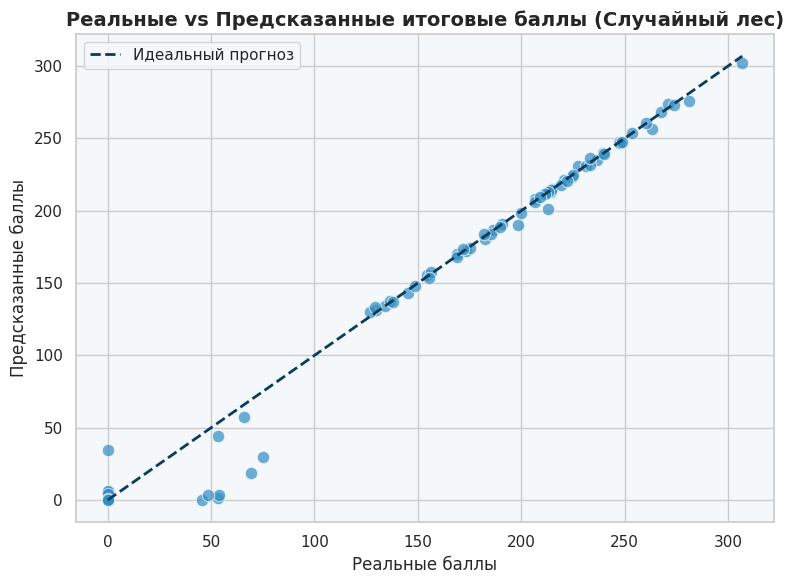

In [18]:
plt.figure(figsize=(8, 6))

# Реальные vs предсказанные значения для Случайного леса
sns.scatterplot(x=y_test, y=y_pred_rf, color="#328CC1", alpha=0.7, s=80)

# предсказание = реальность
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color="#0B3C5D", linestyle='--', linewidth=2, label='Идеальный прогноз')

plt.title('Реальные vs Предсказанные итоговые баллы (Случайный лес)')
plt.xlabel('Реальные баллы')
plt.ylabel('Предсказанные баллы')
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Преобразуем колонку final_rank в числовой формат
df['final_rank'] = pd.to_numeric(df['final_rank'], errors='coerce')

# Создаем целевую переменную: 1, если фигурист в Топ-10 (место <= 10), иначе 0
df['is_top10'] = (df['final_rank'] <= 10).astype(int)

# Признаки (X) и цель (y)
X_cls = df[['tes_total', 'pcs_total']]
y_cls = df['is_top10']

# Делим данные
from sklearn.model_selection import train_test_split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

# Обучаем классификатор
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_c, y_train_c)
y_pred_c = clf.predict(X_test_c)

# Выводим результаты
print("=== Классификация: Попадание в Топ-10 ===")
print(f"Точность (Accuracy): {accuracy_score(y_test_c, y_pred_c):.3f}")
print("\nДетальный отчет:")
print(classification_report(y_test_c, y_pred_c, target_names=['Ниже Топ-10', 'Топ-10']))

=== Классификация: Попадание в Топ-10 ===
Точность (Accuracy): 0.778

Детальный отчет:
              precision    recall  f1-score   support

 Ниже Топ-10       0.81      0.88      0.84        48
      Топ-10       0.70      0.58      0.64        24

    accuracy                           0.78        72
   macro avg       0.75      0.73      0.74        72
weighted avg       0.77      0.78      0.77        72



In [23]:
# Функция для ввода данных с клавиатуры для прогноза
def ask_and_predict():
    print("=== ИНТЕРАКТИВНЫЙ ПРОГНОЗ ===")
    try:
        tes = float(input("Введите баллы за технику (TES): "))
        pcs = float(input("Введите баллы за артистизм (PCS): "))

        # Создаем таблицу
        new_data = pd.DataFrame({'tes_total': [tes], 'pcs_total': [pcs]})

        # Предсказание
        prediction = clf.predict(new_data)[0]
        probability = clf.predict_proba(new_data)[0][1] * 100

        print("\n--- РЕЗУЛЬТАТ ---")
        if prediction == 1:
            print(f"✅ Фигурист с такими баллами ПОПАДЕТ В ТОП-10!")
            print(f"Уверенность модели: {probability:.1f}%")
        else:
            print(f"❌ Фигурист с такими баллами НЕ попадет в ТОП-10.")
            print(f"Уверенность модели: {100 - probability:.1f}%")

    except ValueError:
        print("Ошибка: Пожалуйста, вводите только числа (например, 75.5).")

# Запускаем функцию
ask_and_predict()

=== ИНТЕРАКТИВНЫЙ ПРОГНОЗ ===
Введите баллы за технику (TES): 100
Введите баллы за артистизм (PCS): 80

--- РЕЗУЛЬТАТ ---
❌ Фигурист с такими баллами НЕ попадет в ТОП-10.
Уверенность модели: 90.0%
